# 7. Processamento das Anotações CVAT

## Objetivo
- Ler as anotações revisadas do CVAT (arquivos XML 1.1).
- Gerar máscaras binárias na resolução original da imagem.
- Aplicar o pipeline padrão de pré-processamento (resize mantendo aspect ratio + padding para `1024x1024`) conforme o padrão de treinamento da rede (`src.data.make_dataset`).
- Salvar imagens e máscaras alinhadas no diretório final `data/processed/` para o treinamento do modelo Mix Vision Transformer (PVT).

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET
from pathlib import Path
import pydicom
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

## Funções de Leitura e Desenho de Máscaras
O CVAT XML 1.1 pode conter anotações do tipo `<box>` ou `<polygon>`. Precisamos suportar ambos para o caso do revisor ter desenhado os contornos exatos.

In [2]:
def parse_cvat_xml(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    
    annotations = {}
    for image in root.findall('image'):
        img_name = image.get('name')
        width = int(image.get('width'))
        height = int(image.get('height'))
        
        shapes = []
        # Poligonos
        for poly in image.findall('polygon'):
            points_str = poly.get('points')
            points = []
            for p in points_str.split(';'):
                x, y = map(float, p.split(','))
                points.append((x, y))
            shapes.append({'type': 'polygon', 'points': points})
            
        # Bounding boxes
        for box in image.findall('box'):
            xtl = float(box.get('xtl'))
            ytl = float(box.get('ytl'))
            xbr = float(box.get('xbr'))
            ybr = float(box.get('ybr'))
            # Converter box para poligono de 4 pontos
            points = [(xtl, ytl), (xbr, ytl), (xbr, ybr), (xtl, ybr)]
            shapes.append({'type': 'box', 'points': points})
            
        annotations[img_name] = {
            'width': width,
            'height': height,
            'shapes': shapes
        }
    return annotations

def create_mask_from_shapes(width, height, shapes):
    mask = Image.new('L', (width, height), 0)
    draw = ImageDraw.Draw(mask)
    
    for shape in shapes:
        points = shape['points']
        draw.polygon(points, fill=255)
        
    return np.array(mask)

## Pipeline de Normalização `make_dataset`
Aplicar a mesma lógica de escalonamento usada em `src/data/make_dataset.py` para garantir alinhamento exato entre os pixels de entrada e os rótulos de saída.

In [3]:
def pad_and_resize(img, target_size=1024, is_mask=False):
    h, w = img.shape[:2]
    scale = target_size / max(h, w)
    new_h, new_w = int(h * scale), int(w * scale)
    
    # INTER_NEAREST para máscaras binárias
    interpolation = cv2.INTER_NEAREST if is_mask else cv2.INTER_AREA
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=interpolation)
    
    # Padding central
    if is_mask:
        img_padded = np.zeros((target_size, target_size), dtype=np.uint8)
    else:
        img_padded = np.zeros((target_size, target_size), dtype=img.dtype)
        
    pad_h = (target_size - new_h) // 2
    pad_w = (target_size - new_w) // 2
    img_padded[pad_h:pad_h+new_h, pad_w:pad_w+new_w] = img_resized
    
    return img_padded

## Execução: Geração de Dataset Processado
Ler os XMLs do diretório `cvat_export` e combinar imagens e máscaras.

In [4]:
cvat_dir = Path('../../data/interim/cvat_export')
processed_dir = Path('../../data/processed')
(processed_dir / 'images').mkdir(parents=True, exist_ok=True)
(processed_dir / 'masks').mkdir(parents=True, exist_ok=True)

xml_files = list(cvat_dir.glob('*.xml'))
print(f"Arquivos XML encontrados: {[x.name for x in xml_files]}")

all_annotations = {}
for xml_file in xml_files:
    if xml_file.name == 'cvat_annotations.xml': 
        continue # ignora o template original que não foi revisado
    print(f"Lendo {xml_file.name}...")
    anns = parse_cvat_xml(xml_file)
    all_annotations.update(anns)
    
print(f"Total de imagens anotadas/revisadas: {len(all_annotations)}")

# Mapear todos os DICOMs disponíveis
all_dicoms_dir = Path('../../data/external/inbreast/raw/INbreast Release 1.0/AllDICOMs')
all_dicom_files = list(all_dicoms_dir.glob('*.dcm'))
dicom_map = {d.name.split('_')[0]: str(d) for d in all_dicom_files}

processed_count = 0
for img_name, data in all_annotations.items():
    img_id = img_name.split('_')[0].split('.')[0]
    
    dcm_path = dicom_map.get(img_id)
    if not dcm_path:
        print(f"DICOM não encontrado para {img_name}")
        continue
        
    # Ler imagem bruta e corrigir polaridade
    ds = pydicom.dcmread(dcm_path)
    img_arr = ds.pixel_array.astype(np.float32)
    if getattr(ds, 'PhotometricInterpretation', 'UNKNOWN') == 'MONOCHROME1':
        img_arr = np.max(img_arr) - img_arr
        
    # Normalizar para 8-bit ou 16-bit
    img_norm = (img_arr - np.min(img_arr)) / (np.max(img_arr) - np.min(img_arr) + 1e-8)
    img_uint8 = (img_norm * 255).astype(np.uint8)
    
    # Criar máscara original
    mask_arr = create_mask_from_shapes(data['width'], data['height'], data['shapes'])
    
    # Redimensionar e preencher
    final_img = pad_and_resize(img_uint8, target_size=1024, is_mask=False)
    final_mask = pad_and_resize(mask_arr, target_size=1024, is_mask=True)
    
    # Salvar em processed/
    out_img_path = processed_dir / 'images' / f"{img_id}.png"
    out_mask_path = processed_dir / 'masks' / f"{img_id}.png"
    
    cv2.imwrite(str(out_img_path), final_img)
    cv2.imwrite(str(out_mask_path), final_mask)
    processed_count += 1

print(f"Processamento concluído. {processed_count} pares imagem/máscara salvos em data/processed/")

Arquivos XML encontrados: ['cvat_annotations.xml', 'cadidate_annotations.xml', 'batch_annotations.xml']
Lendo cadidate_annotations.xml...
Lendo batch_annotations.xml...
Total de imagens anotadas/revisadas: 285
Processamento concluído. 285 pares imagem/máscara salvos em data/processed/


## Inspeção Visual dos Dados Processados

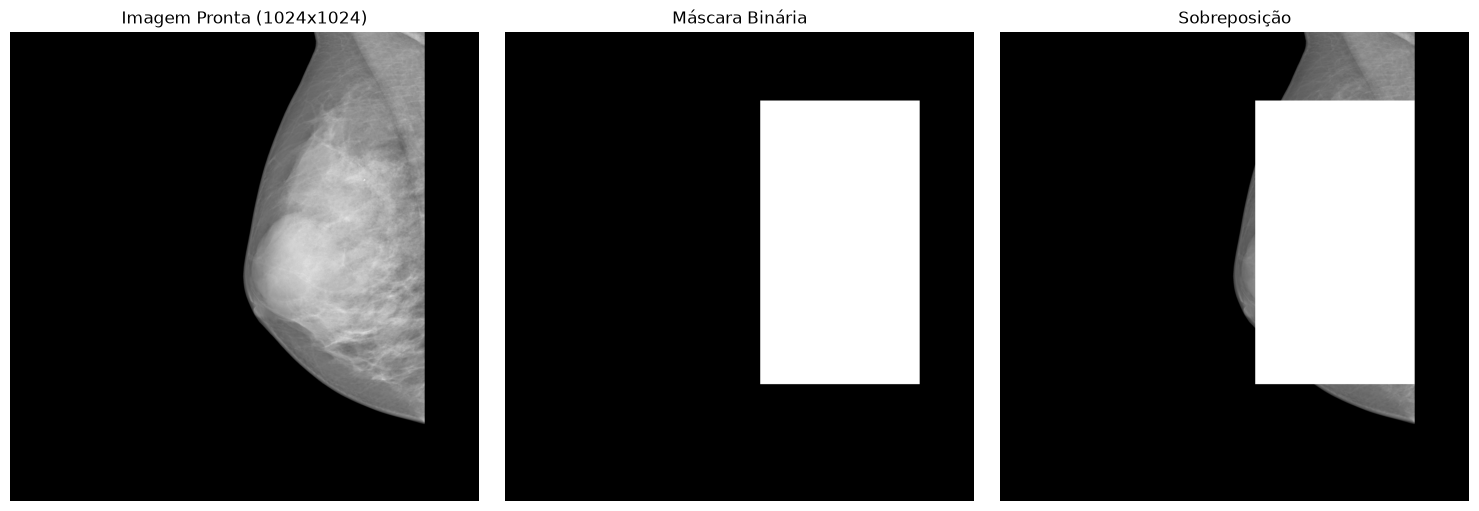

In [5]:
# Visualizar um exemplo
if processed_count > 0:
    sample_id = list(all_annotations.keys())[0].split('.')[0]
    img_show = cv2.imread(str(processed_dir / 'images' / f"{sample_id}.png"), cv2.IMREAD_GRAYSCALE)
    mask_show = cv2.imread(str(processed_dir / 'masks' / f"{sample_id}.png"), cv2.IMREAD_GRAYSCALE)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_show, cmap='gray')
    axes[0].set_title(f"Imagem Pronta (1024x1024)")
    axes[0].axis('off')
    
    axes[1].imshow(mask_show, cmap='gray')
    axes[1].set_title("Máscara Binária")
    axes[1].axis('off')
    
    # Sobreposicao
    overlay = img_show.copy()
    overlay[mask_show > 0] = 255
    axes[2].imshow(overlay, cmap='gray')
    axes[2].set_title("Sobreposição")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()